## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Kamal Sangam

**Date:** Oct 21

### Q1. Token frequency distribution

In [2]:
import pickle
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

data_folder = Path("data")
if not data_folder.exists():
    data_folder = Path(".")

with open(data_folder / "all_tokens.pickle", "rb") as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
frequencies = list(token_count.values())

print("Total tokens:", len(all_tokens))
print("Different tokens:", len(token_count))
print("10 most common tokens:", token_count.most_common(10))

Total tokens: 276949
Different tokens: 48691
10 most common tokens: [('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


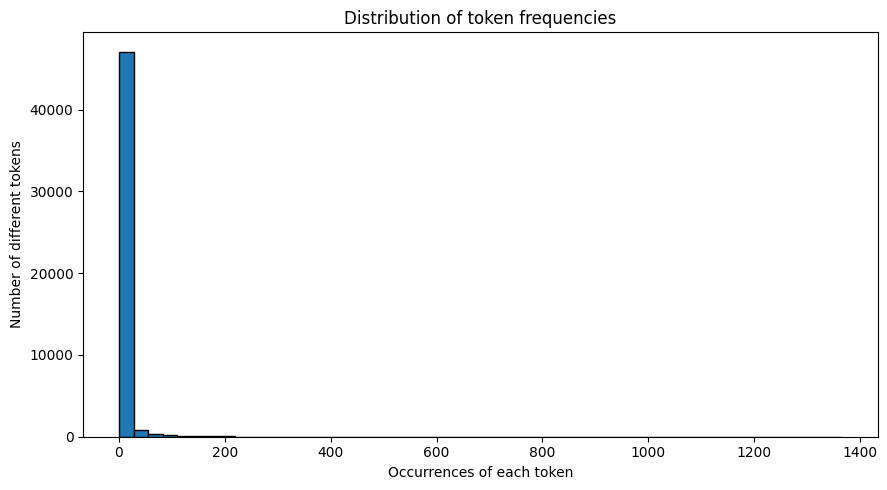

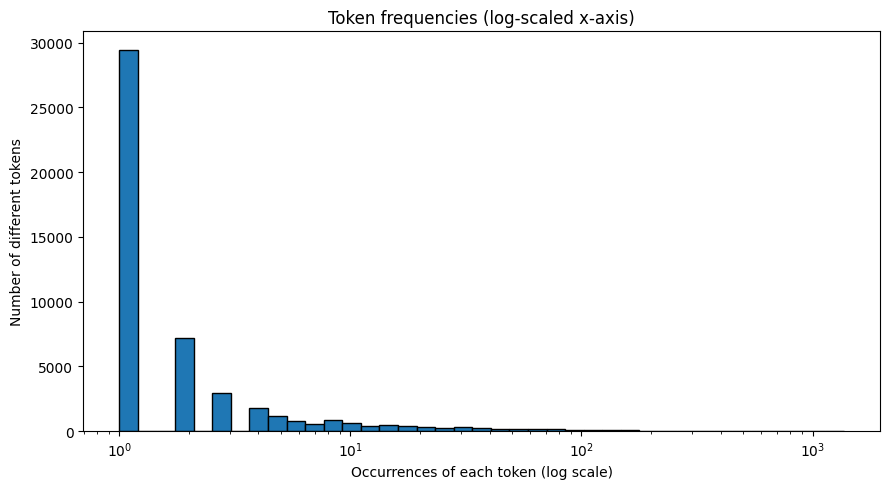

In [2]:
# A histogram shows how many distinct tokens occur a given number of times
plt.figure(figsize=(9, 5))
plt.hist(frequencies, bins=50, edgecolor="black")
plt.xlabel("Occurrences of each token")
plt.ylabel("Number of different tokens")
plt.title("Distribution of token frequencies")
plt.tight_layout()
plt.show()

# A log-scaled x-axis helps show the large range of frequencies
plt.figure(figsize=(9, 5))
plt.hist(frequencies, bins=np.logspace(0, np.log10(max(frequencies)), 40), edgecolor="black")
plt.xscale("log")
plt.xlabel("Occurrences of each token (log scale)")
plt.ylabel("Number of different tokens")
plt.title("Token frequencies (log-scaled x-axis)")
plt.tight_layout()
plt.show()

**Q1 observations:** The distribution is strongly right-skewed: most distinct tokens appear only a few times, while a small number occur much more frequently. This creates a long right tail in the histogram. The second plot uses a log-scaled horizontal axis so the less frequent and very common words are easier to compare.

### Q2. Linear regression using one-hot-encoded tokens

In [4]:
%pip install pyarrow

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.2/31.2 MB 31.2 MB/s  0:00:01m0:00:0100:01

[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Each row is an email. Email Type is the value we want to predict
df = pd.read_parquet(data_folder / "Phishing_clean.parquet")
print("Data shape:", df.shape)
print(df["Email Type"].value_counts())

X = df.drop(columns="Email Type")
y = df["Email Type"]

# 80% training data and 20% test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training emails:", len(X_train))
print("Test emails:", len(X_test))

Data shape: (18634, 2712)
Email Type
0    11322
1     7312
Name: count, dtype: int64
Training emails: 14907
Test emails: 3727


In [4]:
# Fit the regression model and calculate R squared.
model = LinearRegression()
model.fit(X_train, y_train)

train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)
print("Training R-squared:", round(train_r2, 4))
print("Test R-squared:", round(test_r2, 4))

# Find the words whose coefficients have the largest absolute values.
coefficients = pd.Series(model.coef_, index=X.columns)
top_words = coefficients.abs().sort_values(ascending=False).head(15)
print("\nTop 15 tokens by absolute coefficient:")
for word in top_words.index:
    print(word, round(coefficients[word], 4))

Training R-squared: 0.767
Test R-squared: 0.6659

Top 15 tokens by absolute coefficient:
intervention -1.2593
localized 0.8244
thermal 0.747
crawler 0.6962
background-image: -0.6229
helvetica, 0.5986
aging 0.595
form. 0.5769
gray; -0.5745
a:active 0.5745
retrieving -0.5738
zdnet -0.561
{text-decoration: 0.4971
xanaax 0.492
transcript 0.489


**Q2 interpretation:** Larger absolute coefficients mean that the token changes the model prediction more strongly when the other tokens are held fixed. Positive coefficients push the prediction toward phishing (1), while negative coefficients push it toward not phishing (0). The printed table above gives the actual most influential tokens. Compare test R² to training R² to see whether the model generalizes; a much lower test score suggests overfitting. Even though the outcome is binary, this question specifically asks for linear regression, so the predictions are not required to stay between 0 and 1.

### Q3. PCA with two principal components

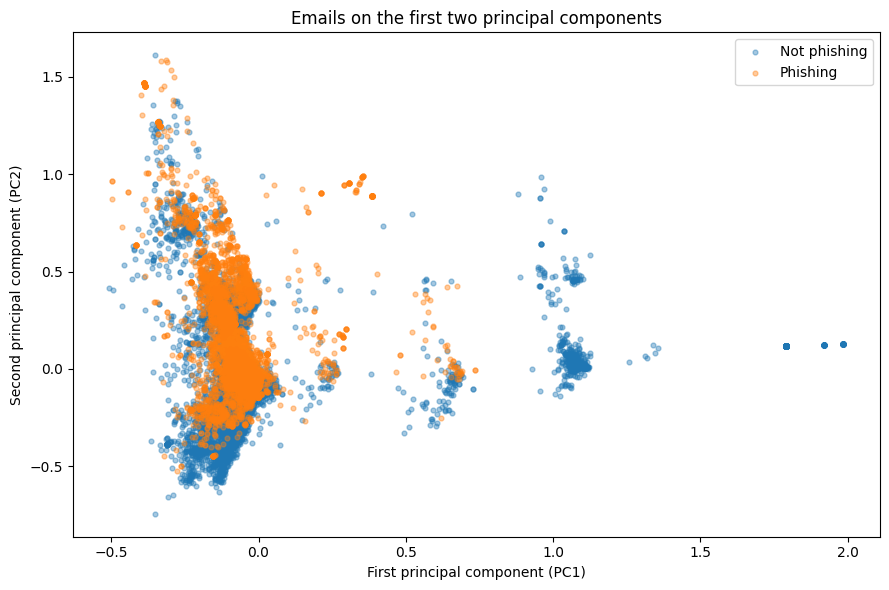

Variance explained by each component: [0.011  0.0087]


In [5]:
# Fit using the training emails so the test set stays unseen
pca_2 = PCA(n_components=2)
pca_2.fit(X_train)

train_2d = pca_2.transform(X_train)
test_2d = pca_2.transform(X_test)

# Combine the transformed points so the plot includes all emails
points_2d = np.concatenate([train_2d, test_2d])
labels = np.concatenate([y_train, y_test])

plt.figure(figsize=(9, 6))
plt.scatter(points_2d[labels == 0, 0], points_2d[labels == 0, 1],
            label="Not phishing", alpha=0.4, s=12)
plt.scatter(points_2d[labels == 1, 0], points_2d[labels == 1, 1],
            label="Phishing", alpha=0.4, s=12)
plt.xlabel("First principal component (PC1)")
plt.ylabel("Second principal component (PC2)")
plt.title("Emails on the first two principal components")
plt.legend()
plt.tight_layout()
plt.show()

print("Variance explained by each component:",
      pca_2.explained_variance_ratio_.round(4))

**Q3 observations:** Look for whether the two colors form separate clusters or overlap. PCA is not told which emails are scams; it looks only for directions with high variation in token usage. Therefore, substantial overlap is possible even if the original tokens can help predict phishing. The printed explained-variance percentages show how much information about the variation is retained by just these two components.

### Q4. Linear regression on the first 2,610 principal components

In [6]:
# Use exactly 2,610 components
# PCA learns the directions from training emails only
pca_large = PCA(n_components=2610)
train_pca = pca_large.fit_transform(X_train)
test_pca = pca_large.transform(X_test)

pca_model = LinearRegression()
pca_model.fit(train_pca, y_train)

pca_train_r2 = pca_model.score(train_pca, y_train)
pca_test_r2 = pca_model.score(test_pca, y_test)
print("PCA training R-squared:", round(pca_train_r2, 4))
print("PCA test R-squared:", round(pca_test_r2, 4))
print("Original training R-squared:", round(train_r2, 4))
print("Original test R-squared:", round(test_r2, 4))

PCA training R-squared: 0.7662
PCA test R-squared: 0.6683
Original training R-squared: 0.767
Original test R-squared: 0.6659


**Q4 interpretation:** Compare the PCA regression test R sqaured printed above with the original regression test R squared. The higher test score indicates which model predicts unseen emails better for this split. Using 2,610 components reduces the number of columns compared with the original 2,711 token columns. However, PCA keeps directions with the most variation, which are not always the directions most useful for predicting phishing.

### Q5. Why use principal components for a high-dimensional regression?

**Answer:** Each email has thousands of token columns, and many words can occur together. This makes the original data high-dimensional and can make the regression harder to work with. PCA replaces the original columns with new components that capture patterns in how the tokens vary. The components are uncorrelated, which helps with redundant information, and using fewer components can make the model smaller and faster. One downside is that the components are harder to explain than individual words, and PCA might leave out patterns that are useful for identifying phishing. That is why it is important to compare the test R² instead of assuming PCA will always improve the result.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 7249539f909fdcfe0d3fe326f73554ec7c5b0f39
- **AI tool and model used:** ChatGPT's GPT-6

### *Prompts used

1. Review my Phase 1 PCA and phishing-email notebook against the Q1–Q5 rubric. Suggest improvements that strengthen correctness or interpretation.

### *AI-proposed changes*

1. **Q1:** Print helpful summary statistics (median, maximum, and fraction of tokens appearing once) to support observations rather than relying only on the histograms.
2. **Q2:** Use a stratified 80/20 split so both sets have a similar share of phishing and non-phishing emails, and print class counts to verify.
3. **Q2:** Give the strongest coefficients in a readable table and explain that coefficient size does not prove causal influence.
4. **Q3:** Label plot groups based on the actual `Email Type` values rather than assuming labels are always 0 and 1.
5. **Q4:** Print the difference between PCA and original regression test R², with an automatic plain-language comparison.
6. **Q1:** Change histogram bars to a rainbow palette.
7. **Q3:** Add decorative plot gradients and shadows.
8. **Q4:** Add a 3D plot of the first three principal components.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1. Q1 descriptive statistics | **Accept** | Directly supports the Q1 observations; verify printed statistics against token frequencies. |
| 2. Q2 stratified split | **Accept** | Helps both sets represent each class while preserving the required 80/20 split; verify class counts and split sizes. |
| 3. Q2 coefficient table | **Accept** | Makes the most important absolute coefficients easier to interpret for Q2.6; check signs and absolute-value ordering. |
| 4. Q3 actual class labels | **Accept** | Prevents incorrect color categories if labels are not coded as 0 and 1; check `Email Type` counts. |
| 5. Q4 numerical comparison | **Accept** | Directly addresses Q4.5; check difference matches the printed R² scores. |
| 6. Rainbow histogram | **Reject** | Cosmetic only; makes bars harder to compare and has no rubric benefit. |
| 7. Gradient/shadow scatter plot | **Reject** | Cosmetic clutter can obscure overlapping PCA points. |
| 8. 3D PCA plot | **Reject** | The rubric specifically asks for the *first two* components, and 3D is harder to read. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

#### Q1. Token frequency distribution (revised)

In [7]:
import pickle
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

# The two uploaded data files are stored in the data folder.
data_folder = Path("data")
if not data_folder.exists():
    data_folder = Path(".")

with open(data_folder / "all_tokens.pickle", "rb") as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
frequencies = list(token_count.values())

print("Total tokens:", len(all_tokens))
print("Different tokens:", len(token_count))
print("10 most common tokens:", token_count.most_common(10))

# Accepted change 1: Numbers to support the written observations.
print("Median occurrences per token:", np.median(frequencies))
print("Most occurrences of one token:", max(frequencies))
print("Percent of distinct tokens appearing once:",
      round(100 * frequencies.count(1) / len(frequencies), 2))


Total tokens: 276949
Different tokens: 48691
10 most common tokens: [('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]
Median occurrences per token: 1.0
Most occurrences of one token: 1365
Percent of distinct tokens appearing once: 60.39


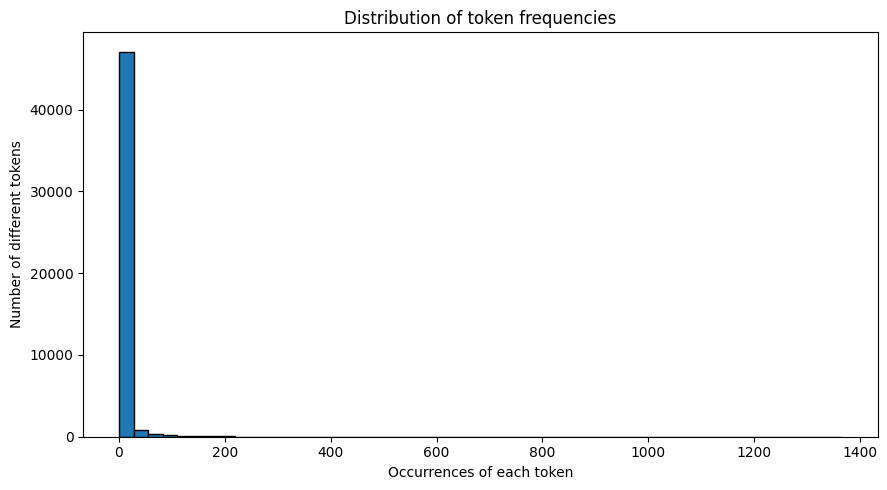

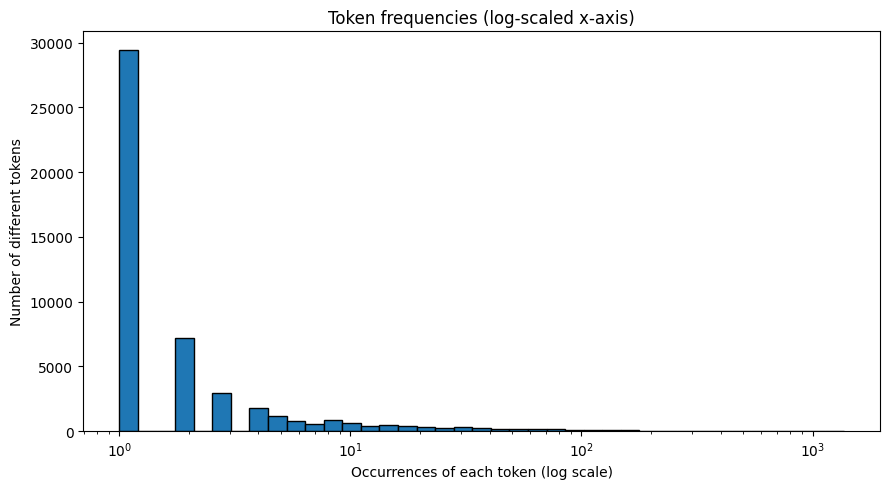

In [8]:
# Histogram of the number of occurrences of each token.
plt.figure(figsize=(9, 5))
plt.hist(frequencies, bins=50, edgecolor="black")
plt.xlabel("Occurrences of each token")
plt.ylabel("Number of different tokens")
plt.title("Distribution of token frequencies")
plt.tight_layout()
plt.show()

# A logarithmic x-axis makes high counts easier to see.
plt.figure(figsize=(9, 5))
plt.hist(frequencies, bins=np.logspace(0, np.log10(max(frequencies)), 40),
         edgecolor="black")
plt.xscale("log")
plt.xlabel("Occurrences of each token (log scale)")
plt.ylabel("Number of different tokens")
plt.title("Token frequencies (log-scaled x-axis)")
plt.tight_layout()
plt.show()

**Q1 observations:** Token frequencies are very uneven: many distinct tokens occur infrequently, while a much smaller set occurs many times. This gives the distribution a long right tail. The second histogram uses a log-scaled x-axis to show that spread more clearly. Use the median, maximum, and percentage appearing once printed above to describe the dataset with specific numbers after running the code.

#### Q2. Linear regression using one-hot-encoded tokens (revised)

In [ ]:
# Each row is an email; Email Type is the outcome we want to predict.
df = pd.read_parquet(data_folder / "Phishing_clean.parquet")
print("Data shape:", df.shape)
print("Email types:")
print(df["Email Type"].value_counts())

X = df.drop(columns="Email Type")
y = df["Email Type"]

# Accepted change 2: Keep the proportions of email types similar in each set.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training emails:", len(X_train))
print("Test emails:", len(X_test))
print("Training class counts:")
print(y_train.value_counts())
print("Test class counts:")
print(y_test.value_counts())

In [ ]:
# Fit the regression model and calculate R-squared.
model = LinearRegression()
model.fit(X_train, y_train)

train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)
print("Training R-squared:", round(train_r2, 4))
print("Test R-squared:", round(test_r2, 4))

# Accepted change 3: A small table makes the coefficient signs easier to see.
coefficients = pd.Series(model.coef_, index=X.columns)
top_words = coefficients.abs().sort_values(ascending=False).head(15)
coefficient_table = pd.DataFrame({
    "Coefficient": coefficients[top_words.index],
    "Absolute coefficient": top_words
})
print("Top 15 tokens by absolute coefficient:")
print(coefficient_table.round(4))

**Q2 interpretation:** The train and test R² values describe how well the regression fits known and unseen emails. The tokens in the table have the largest absolute coefficients in this fitted model. Positive coefficients increase the predicted numeric outcome, and negative coefficients decrease it; what that means for phishing depends on how `Email Type` is coded. These are model associations, not proof that a word causes phishing.

#### Q3. PCA with two principal components (revised)

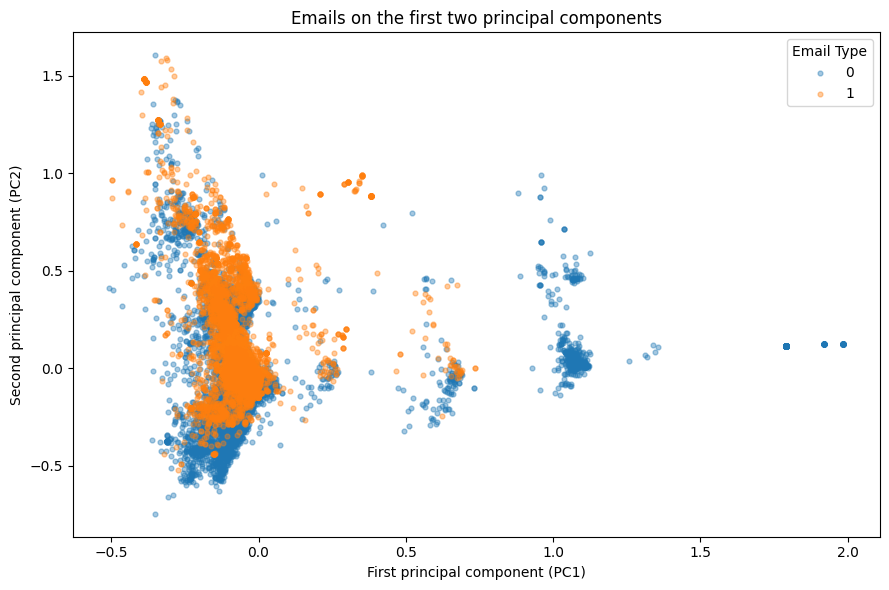

Variance explained by each component: [0.011  0.0087]


In [9]:
# PCA.fit() finds the directions and PCA.transform() creates scores.
# Use the training set to learn the components (avoids test leakage).
pca_2 = PCA(n_components=2)
pca_2.fit(X_train)
train_2d = pca_2.transform(X_train)
test_2d = pca_2.transform(X_test)

# Combine both sets so every email is included in the plot.
points_2d = np.concatenate([train_2d, test_2d])
labels = np.concatenate([y_train, y_test])

# Accepted change 4: Plot the actual target values rather than assuming 0/1.
plt.figure(figsize=(9, 6))
for email_type in np.unique(labels):
    matching = labels == email_type
    plt.scatter(points_2d[matching, 0], points_2d[matching, 1],
                label=str(email_type), alpha=0.4, s=12)

plt.xlabel("First principal component (PC1)")
plt.ylabel("Second principal component (PC2)")
plt.title("Emails on the first two principal components")
plt.legend(title="Email Type")
plt.tight_layout()
plt.show()

print("Variance explained by each component:",
      pca_2.explained_variance_ratio_.round(4))

**Q3 observations:** The axes represent the two directions with the greatest variation in the one-hot token features. Inspect the scatter plot to see how much the phishing and non-phishing categories overlap. If the colors overlap, two components alone do not cleanly separate them. PCA is unsupervised: it is not designed to maximize differences between phishing labels.

#### Q4. Regression on the first 2,610 principal components (revised)

In [10]:
# The assignment asks for exactly 2,610 components.
# This requires at least 2,610 training rows and feature columns.
pca_large = PCA(n_components=2610)
train_pca = pca_large.fit_transform(X_train)
test_pca = pca_large.transform(X_test)

pca_model = LinearRegression()
pca_model.fit(train_pca, y_train)

pca_train_r2 = pca_model.score(train_pca, y_train)
pca_test_r2 = pca_model.score(test_pca, y_test)
print("PCA training R-squared:", round(pca_train_r2, 4))
print("PCA test R-squared:", round(pca_test_r2, 4))
print("Original training R-squared:", round(train_r2, 4))
print("Original test R-squared:", round(test_r2, 4))

# Accepted change 5: Print an exact comparison on the test set.
difference = pca_test_r2 - test_r2
print("PCA minus original test R-squared:", round(difference, 4))
if difference > 0:
    print("The PCA model had a higher test R-squared.")
elif difference < 0:
    print("The original model had a higher test R-squared.")
else:
    print("Both models had the same test R-squared.")

PCA training R-squared: 0.7662
PCA test R-squared: 0.6683
Original training R-squared: 0.767
Original test R-squared: 0.6659
PCA minus original test R-squared: 0.0025
The PCA model had a higher test R-squared.


**Q4 interpretation:** The printed test R² difference tells us which approach performed better on the held-out test set. A positive value means the 2,610-component regression did better; a negative value means the original token regression did better. Compare training R² as well: a large training-to-test drop suggests the model does not generalize as well as its training fit suggests. Because both models use the same split, the comparison is more meaningful.

#### Q5. Advantage of principal components

**Answer:** Emails have thousands of one-hot token columns, and many words often appear together. PCA replaces these original columns with new components that summarize patterns in the data. The components are uncorrelated, so they reduce redundant information. If we keep fewer components, regression can also use fewer features, which may make it easier to work with. However, the components are harder to interpret than actual words, and PCA can remove useful information. PCA does not automatically improve test R², so I would compare both models on the test set to decide whether it helped.

### *Reflection on AI assistance
In your own words without generative AI.

> I used AI to review the Phase 1 notebook against the assignment rubric and decide which suggestions would make my analysis clearer or more reliable. The most useful improvements were adding numerical summaries for the token frequencies, making the train-test split stratified, and showing the strongest regression coefficients in a table. The frequency summaries make my Q1 explanation more specific, while the stratified split helps keep the proportions of email types similar across training and testing data. I also liked using the actual email labels in the PCA scatter plot so I would not accidentally assign the wrong colors.
>
> I rejected some suggestions that were mainly visual, including rainbow-colored histograms, gradients, and a 3D PCA plot. Those changes would not improve the rubric requirements and might make the plots more difficult to read. I also learned that PCA does not always improve regression performance just because it reduces the number of features.
>
> To check the revised work, I ran the cells, checked the PCA plot, and checked the code. One remaining limitation is that the model coefficients show associations, not necessarily causal relationships between words and phishing.